# Path Analysis: Understanding Direct and Indirect Effects on Academic Performance

This Notebook applies Path Analysis to study how lifestyle and learning behaviors may be related to academic performance through direct and indirect pathways.

# パス解析：生活習慣・学習行動が学業成果へ与える直接効果・間接効果を理解する

このNotebookでは、生活習慣や学習行動が、どのような経路を通じて学業成果と関連するのかをパス解析で確認します。

## 1. Learning Objectives / 学習目標

- Understand Path Analysis
- Distinguish direct, indirect, and total effects
- Express a path model as multiple regression equations
- Estimate standardized path coefficients
- Calculate indirect effects
- Visualize a path diagram
- Understand limitations of causal interpretation
- Connect Path Analysis to SEM

- パス解析の考え方を理解する
- 直接効果・間接効果・総効果を理解する
- 仮説モデルを複数の回帰式で表現する
- 標準化パス係数を推定する
- 間接効果を計算する
- パス図を可視化する
- 因果解釈の限界を理解する
- SEMとのつながりを理解する

## 2. Use Case / ユースケース

A school wants to understand how students' lifestyle and learning behaviors are related to exam performance.

The conceptual model assumes:

- Sleep and attendance affect study time
- Sleep, attendance, and study time affect self-efficacy
- Study time, attendance, self-efficacy, and sleep affect exam score

学校が、生活習慣・学習行動・心理的要因が試験得点へどのようにつながるかを分析するケースです。

今回の仮説は次の流れです。

`Sleep / Attendance → Study Hours → Self-Efficacy → Exam Score`

ただし、一部には直接効果もあるものとします。

## 3. What Is Path Analysis? / パス解析とは

Path Analysis represents hypothesized relationships among observed variables using a system of regression equations.

Unlike a single multiple regression, it can separate:

- direct effects
- indirect effects
- total effects

パス解析は、観測変数同士の関係を複数の回帰式で表し、直接効果と間接効果を分けて考える方法です。

## 4. Direct, Indirect, and Total Effects / 直接効果・間接効果・総効果

For a simple mediation path:

`X → M → Y`

If:

- X → M = a
- M → Y = b
- X → Y = c'

then:

- Direct effect = c'
- Indirect effect = a × b
- Total effect = c' + a × b

媒介変数Mを経由する効果は、経路上のパス係数を掛け合わせて求めます。

## 5. Conceptual Path Model / 今回の仮説モデル

Directed paths:

- Sleep → Study Hours
- Attendance → Study Hours
- Sleep → Self-Efficacy
- Attendance → Self-Efficacy
- Study Hours → Self-Efficacy
- Sleep → Exam Score
- Attendance → Exam Score
- Study Hours → Exam Score
- Self-Efficacy → Exam Score

SleepとAttendanceを外生変数、Study HoursとSelf-Efficacyを媒介変数、Exam Scoreを結果変数として扱います。

## 6. Import Libraries / ライブラリの読み込み

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
pd.set_option("display.max_columns", None)

## 7. Load the Dataset / データの読み込み

In [2]:
paths=[Path("../data/student_path_model.csv"),Path("12_path_analysis/data/student_path_model.csv"),Path("data/student_path_model.csv")]
data_path=next((p for p in paths if p.exists()),None)
if data_path is None: raise FileNotFoundError("student_path_model.csv was not found.")
df=pd.read_csv(data_path)
df.head()

,student_id,sleep_hours,attendance_rate,study_hours_week,self_efficacy,exam_score
0,S001,7.07,100.00,10.85,66.89,97.45
1,S002,5.86,77.26,4.25,42.94,83.81
2,S003,7.48,94.05,12.22,65.46,100.00
3,S004,7.65,85.70,7.65,63.38,96.01
4,S005,5.04,87.57,4.22,41.07,84.35


## 8. Understand the Dataset / データの確認

In [3]:
print("Shape:",df.shape)
df.info()

Shape: (300, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        300 non-null    object 
 1   sleep_hours       300 non-null    float64
 2   attendance_rate   300 non-null    float64
 3   study_hours_week  300 non-null    float64
 4   self_efficacy     300 non-null    float64
 5   exam_score        300 non-null    float64
dtypes: float64(5), object(1)
memory usage: 14.2+ KB


In [4]:
df.isna().sum()

student_id          0
sleep_hours         0
attendance_rate     0
study_hours_week    0
self_efficacy       0
exam_score          0
dtype: int64

In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
sleep_hours,300.0,6.76,0.83,4.50,6.20,6.72,7.22,9.00
attendance_rate,300.0,87.83,6.94,67.25,83.04,88.42,92.74,100.00
study_hours_week,300.0,7.77,2.33,2.24,6.32,7.72,9.45,15.19
self_efficacy,300.0,54.64,7.80,30.27,49.06,54.92,60.06,80.12
exam_score,300.0,94.01,5.36,77.15,90.63,94.96,99.26,100.00


## 9. Correlation Matrix / 相関行列

In [6]:
variables=["sleep_hours","attendance_rate","study_hours_week","self_efficacy","exam_score"]
corr=df[variables].corr()
corr.round(3)

,sleep_hours,attendance_rate,study_hours_week,self_efficacy,exam_score
sleep_hours,1.000,0.034,0.449,0.500,0.352
attendance_rate,0.034,1.000,0.255,0.388,0.405
study_hours_week,0.449,0.255,1.000,0.720,0.591
self_efficacy,0.500,0.388,0.720,1.000,0.553
exam_score,0.352,0.405,0.591,0.553,1.000


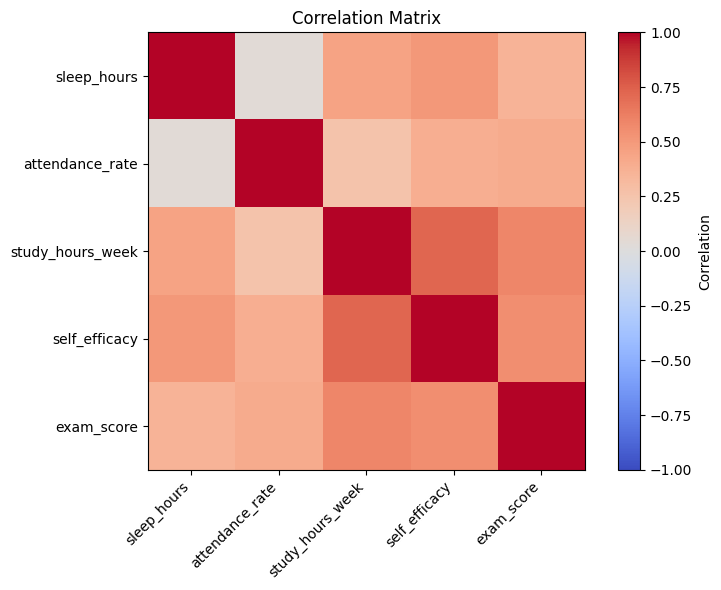

In [7]:
fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(corr.values,vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(range(len(variables)),labels=variables,rotation=45,ha="right")
ax.set_yticks(range(len(variables)),labels=variables)
fig.colorbar(im,ax=ax,label="Correlation")
ax.set_title("Correlation Matrix")
plt.tight_layout(); plt.show()

## 10. Standardize the Variables / 変数を標準化する

Path coefficients are often reported as standardized regression coefficients.

Standardization allows coefficients to be compared despite different units.

パス係数は標準化係数で表すことが多いため、各変数を平均0・標準偏差1に標準化します。

In [8]:
scaler=StandardScaler()
z=pd.DataFrame(scaler.fit_transform(df[variables]),columns=variables,index=df.index)
z.head()

,sleep_hours,attendance_rate,study_hours_week,self_efficacy,exam_score
0,0.374700,1.757668,1.325786,1.572161,0.641948
1,-1.088310,-1.526595,-1.510856,-1.502294,-1.905004
2,0.870430,0.898329,1.914604,1.388592,1.118101
3,1.075977,-0.307634,-0.049555,1.121583,0.373061
4,-2.079771,-0.037556,-1.523750,-1.742345,-1.804172


## 11. Regression Equation 1: Study Hours / 回帰式1：学習時間

`Study Hours = Sleep + Attendance + error`

This equation estimates how the two exogenous variables relate to study time.

睡眠時間と出席率が、週あたり学習時間とどう関連するかを推定します。

In [9]:
X1=sm.add_constant(z[["sleep_hours","attendance_rate"]])
m1=sm.OLS(z["study_hours_week"],X1).fit()
print(m1.summary())

                            OLS Regression Results                            
Dep. Variable:       study_hours_week   R-squared:                       0.259
Model:                            OLS   Adj. R-squared:                  0.254
Method:                 Least Squares   F-statistic:                     52.04
Date:                Sat, 12 Sep 2026   Prob (F-statistic):           4.23e-20
Time:                        09:37:57   Log-Likelihood:                -380.62
No. Observations:                 300   AIC:                             767.2
Df Residuals:                     297   BIC:                             778.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const           -3.383e-16      0.050  -6.

## 12. Regression Equation 2: Self-Efficacy / 回帰式2：自己効力感

`Self-Efficacy = Sleep + Attendance + Study Hours + error`

Study Hours now acts as a mediator.

学習時間が媒介変数として自己効力感に影響するモデルです。

In [10]:
X2=sm.add_constant(z[["sleep_hours","attendance_rate","study_hours_week"]])
m2=sm.OLS(z["self_efficacy"],X2).fit()
print(m2.summary())

                            OLS Regression Results                            
Dep. Variable:          self_efficacy   R-squared:                       0.611
Model:                            OLS   Adj. R-squared:                  0.607
Method:                 Least Squares   F-statistic:                     155.2
Date:                Sat, 12 Sep 2026   Prob (F-statistic):           1.97e-60
Time:                        09:37:57   Log-Likelihood:                -283.94
No. Observations:                 300   AIC:                             575.9
Df Residuals:                     296   BIC:                             590.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -4.415e-16      0.036  

## 13. Regression Equation 3: Exam Score / 回帰式3：試験得点

`Exam Score = Sleep + Attendance + Study Hours + Self-Efficacy + error`

This equation estimates the direct effects on the final outcome.

最終結果である試験得点に対する直接パスを推定します。

In [11]:
X3=sm.add_constant(z[["sleep_hours","attendance_rate","study_hours_week","self_efficacy"]])
m3=sm.OLS(z["exam_score"],X3).fit()
print(m3.summary())

                            OLS Regression Results                            
Dep. Variable:             exam_score   R-squared:                       0.439
Model:                            OLS   Adj. R-squared:                  0.431
Method:                 Least Squares   F-statistic:                     57.67
Date:                Sat, 12 Sep 2026   Prob (F-statistic):           6.44e-36
Time:                        09:37:57   Log-Likelihood:                -339.02
No. Observations:                 300   AIC:                             688.0
Df Residuals:                     295   BIC:                             706.6
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -6.731e-16      0.044  

## 14. Collect Standardized Path Coefficients / 標準化パス係数をまとめる

In [12]:
paths_table=pd.DataFrame([
    ["Sleep","Study Hours",m1.params["sleep_hours"]],
    ["Attendance","Study Hours",m1.params["attendance_rate"]],
    ["Sleep","Self-Efficacy",m2.params["sleep_hours"]],
    ["Attendance","Self-Efficacy",m2.params["attendance_rate"]],
    ["Study Hours","Self-Efficacy",m2.params["study_hours_week"]],
    ["Sleep","Exam Score",m3.params["sleep_hours"]],
    ["Attendance","Exam Score",m3.params["attendance_rate"]],
    ["Study Hours","Exam Score",m3.params["study_hours_week"]],
    ["Self-Efficacy","Exam Score",m3.params["self_efficacy"]],
],columns=["from","to","standardized_path_coefficient"])
paths_table.round(3)

,from,to,standardized_path_coefficient
0,Sleep,Study Hours,0.441
1,Attendance,Study Hours,0.240
2,Sleep,Self-Efficacy,0.246
3,Attendance,Self-Efficacy,0.240
4,Study Hours,Self-Efficacy,0.549
5,Sleep,Exam Score,0.108
6,Attendance,Exam Score,0.256
7,Study Hours,Exam Score,0.394
8,Self-Efficacy,Exam Score,0.116


## 15. Interpret Direct Effects / 直接効果の解釈

A standardized path coefficient indicates how many standard deviations the destination variable changes when the source variable increases by one standard deviation, holding other predictors constant.

標準化パス係数は、他の説明変数を一定としたとき、ある変数が1標準偏差増えると結果変数が何標準偏差変化するかを表します。

## 16. Calculate Indirect Effects / 間接効果を計算する

Example:

`Study Hours → Self-Efficacy → Exam Score`

Indirect effect =

`(Study Hours → Self-Efficacy) × (Self-Efficacy → Exam Score)`

経路上のパス係数を掛け合わせることで、媒介効果を表現できます。

In [13]:
a_study_eff=m2.params["study_hours_week"]
b_eff_exam=m3.params["self_efficacy"]
indirect_study_via_eff=a_study_eff*b_eff_exam

direct_study=m3.params["study_hours_week"]
total_study=direct_study+indirect_study_via_eff

pd.DataFrame({
    "effect":["Direct","Indirect via Self-Efficacy","Total"],
    "value":[direct_study,indirect_study_via_eff,total_study]
}).round(3)

,effect,value
0,Direct,0.394
1,Indirect via Self-Efficacy,0.063
2,Total,0.458


## 17. Sleep: Multiple Indirect Paths / 睡眠時間の複数の間接経路

Sleep can affect Exam Score through several paths:

1. Sleep → Study Hours → Exam Score
2. Sleep → Self-Efficacy → Exam Score
3. Sleep → Study Hours → Self-Efficacy → Exam Score

パス解析では、複数の間接経路を分解できる点が重要です。

In [14]:
sleep_study=m1.params["sleep_hours"]
study_exam=m3.params["study_hours_week"]
sleep_eff=m2.params["sleep_hours"]
study_eff=m2.params["study_hours_week"]
eff_exam=m3.params["self_efficacy"]

ind1=sleep_study*study_exam
ind2=sleep_eff*eff_exam
ind3=sleep_study*study_eff*eff_exam
direct_sleep=m3.params["sleep_hours"]
total_sleep=direct_sleep+ind1+ind2+ind3

pd.DataFrame({
    "path":[
        "Direct: Sleep → Exam",
        "Sleep → Study → Exam",
        "Sleep → Self-Efficacy → Exam",
        "Sleep → Study → Self-Efficacy → Exam",
        "Total"
    ],
    "effect":[direct_sleep,ind1,ind2,ind3,total_sleep]
}).round(3)

,path,effect
0,Direct: Sleep → Exam,0.108
1,Sleep → Study → Exam,0.174
2,Sleep → Self-Efficacy → Exam,0.028
3,Sleep → Study → Self-Efficacy → Exam,0.028
4,Total,0.339


## 18. Attendance: Direct and Indirect Effects / 出席率の直接・間接効果

Attendance also has multiple possible routes to Exam Score.

出席率についても、直接効果と媒介効果を分解します。

In [15]:
att_study=m1.params["attendance_rate"]
att_eff=m2.params["attendance_rate"]

att_ind1=att_study*study_exam
att_ind2=att_eff*eff_exam
att_ind3=att_study*study_eff*eff_exam
direct_att=m3.params["attendance_rate"]
total_att=direct_att+att_ind1+att_ind2+att_ind3

pd.DataFrame({
    "path":[
        "Direct: Attendance → Exam",
        "Attendance → Study → Exam",
        "Attendance → Self-Efficacy → Exam",
        "Attendance → Study → Self-Efficacy → Exam",
        "Total"
    ],
    "effect":[direct_att,att_ind1,att_ind2,att_ind3,total_att]
}).round(3)

,path,effect
0,Direct: Attendance → Exam,0.256
1,Attendance → Study → Exam,0.095
2,Attendance → Self-Efficacy → Exam,0.028
3,Attendance → Study → Self-Efficacy → Exam,0.015
4,Total,0.393


## 19. R² for Each Endogenous Variable / 各内生変数のR²

Each regression equation has its own R².

R² indicates how much variance of each endogenous variable is explained by its predictors.

各内生変数について、それまでの変数群でどの程度説明できているかを確認します。

In [16]:
pd.DataFrame({
    "endogenous_variable":["Study Hours","Self-Efficacy","Exam Score"],
    "R2":[m1.rsquared,m2.rsquared,m3.rsquared]
}).round(3)

,endogenous_variable,R2
0,Study Hours,0.259
1,Self-Efficacy,0.611
2,Exam Score,0.439


## 20. Visualize the Path Diagram / パス図を可視化する

A path diagram helps us see the model structure.

Arrow labels show standardized path coefficients.

矢印の横に標準化パス係数を表示します。

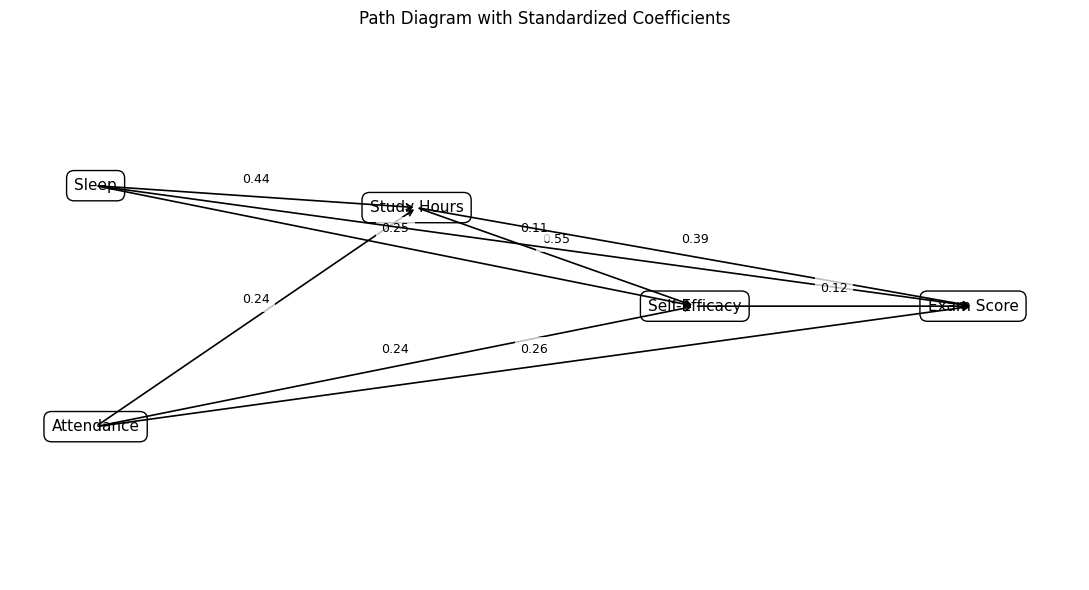

In [17]:
fig,ax=plt.subplots(figsize=(11,6))
pos={
    "Sleep":(0.08,0.72),
    "Attendance":(0.08,0.28),
    "Study Hours":(0.38,0.68),
    "Self-Efficacy":(0.64,0.50),
    "Exam Score":(0.90,0.50),
}
for node,(x,y) in pos.items():
    ax.text(x,y,node,ha="center",va="center",
            bbox=dict(boxstyle="round,pad=0.5",fc="white",ec="black"),
            fontsize=11)

edges=[
("Sleep","Study Hours",m1.params["sleep_hours"]),
("Attendance","Study Hours",m1.params["attendance_rate"]),
("Sleep","Self-Efficacy",m2.params["sleep_hours"]),
("Attendance","Self-Efficacy",m2.params["attendance_rate"]),
("Study Hours","Self-Efficacy",m2.params["study_hours_week"]),
("Sleep","Exam Score",m3.params["sleep_hours"]),
("Attendance","Exam Score",m3.params["attendance_rate"]),
("Study Hours","Exam Score",m3.params["study_hours_week"]),
("Self-Efficacy","Exam Score",m3.params["self_efficacy"]),
]

for src,dst,beta in edges:
    x1,y1=pos[src]; x2,y2=pos[dst]
    ax.annotate("",xy=(x2,y2),xytext=(x1,y1),
                arrowprops=dict(arrowstyle="->",lw=1.2))
    mx,my=(x1+x2)/2,(y1+y2)/2
    ax.text(mx,my+0.025,f"{beta:.2f}",fontsize=9,ha="center",
            bbox=dict(fc="white",ec="none",alpha=0.75))

ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis("off")
ax.set_title("Path Diagram with Standardized Coefficients")
plt.tight_layout(); plt.show()

## 21. Path Analysis vs Multiple Regression / パス解析と重回帰の違い

Multiple regression usually focuses on one outcome equation.

Path Analysis combines several regression equations into one hypothesized system.

This allows us to discuss:

- mediators
- direct effects
- indirect effects
- total effects

重回帰が1つの結果変数を中心に見るのに対し、パス解析は複数の回帰式をつなぎ、変数間の経路全体を分析します。

## 22. Path Analysis vs SEM / パス解析とSEM

Path Analysis uses observed variables.

Structural Equation Modeling (SEM) extends this idea to include:

- latent variables
- measurement models
- structural models
- global model-fit statistics

パス解析はすべて観測変数を使うのが基本です。

次章のSEMでは、直接観測できない「潜在変数」までモデルに組み込みます。

つまり、

> Path Analysis is a special case of SEM.

と考えることができます。

## 23. Important Warning: Association Is Not Causation / 重要：関連は因果を保証しない

Drawing arrows does not prove causality.

A valid causal interpretation requires strong assumptions such as:

- correct temporal ordering
- no important omitted confounders
- correct model specification
- appropriate study design

矢印を書いたからといって因果関係が証明されるわけではありません。

パス解析は「仮説として置いた因果構造がデータとどう対応するか」を分析するものであり、観察データだけで因果を断定することはできません。

## 24. Assumptions and Limitations / 前提条件と限界

Important considerations:

- relationships are assumed to be approximately linear
- residual assumptions of regression still matter
- model specification is determined by the analyst
- omitted variables can bias path coefficients
- reciprocal causation is not handled by this simple recursive model
- indirect effects should ideally be evaluated with confidence intervals, often using bootstrap methods
- the current dataset is simulated
- statistical significance does not establish causality

主な注意点は、線形性、回帰モデルの前提、変数漏れ、モデル設定の妥当性、因果解釈です。

今回のNotebookでは仕組みを理解することを優先し、ブートストラップによる間接効果の信頼区間などは発展内容とします。

## 25. Conclusion / まとめ

This Notebook used Path Analysis to examine how lifestyle and learning variables are connected to academic performance.

Workflow:

1. Define a conceptual path model
2. Inspect correlations
3. Standardize variables
4. Estimate each regression equation
5. Extract standardized path coefficients
6. Calculate direct effects
7. Calculate indirect effects
8. Calculate total effects
9. Review R²
10. Visualize the path diagram
11. Discuss causal limitations
12. Connect Path Analysis to SEM

The key idea is:

> A relationship can be decomposed into direct and mediated pathways.

この章の最重要ポイントは、

> 「AがYに効く」という1本の関係だけでなく、AがMを経由してYへ届く間接経路まで分解できる

という点です。

次章では、この考え方を潜在変数まで拡張したStructural Equation Modeling（SEM）へ進みます。